<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter3/mass_hanging_motion_large_trajectory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Radial Oscillations vs Rotational Motion of $m$ under large oscillations of $m_{2}$.

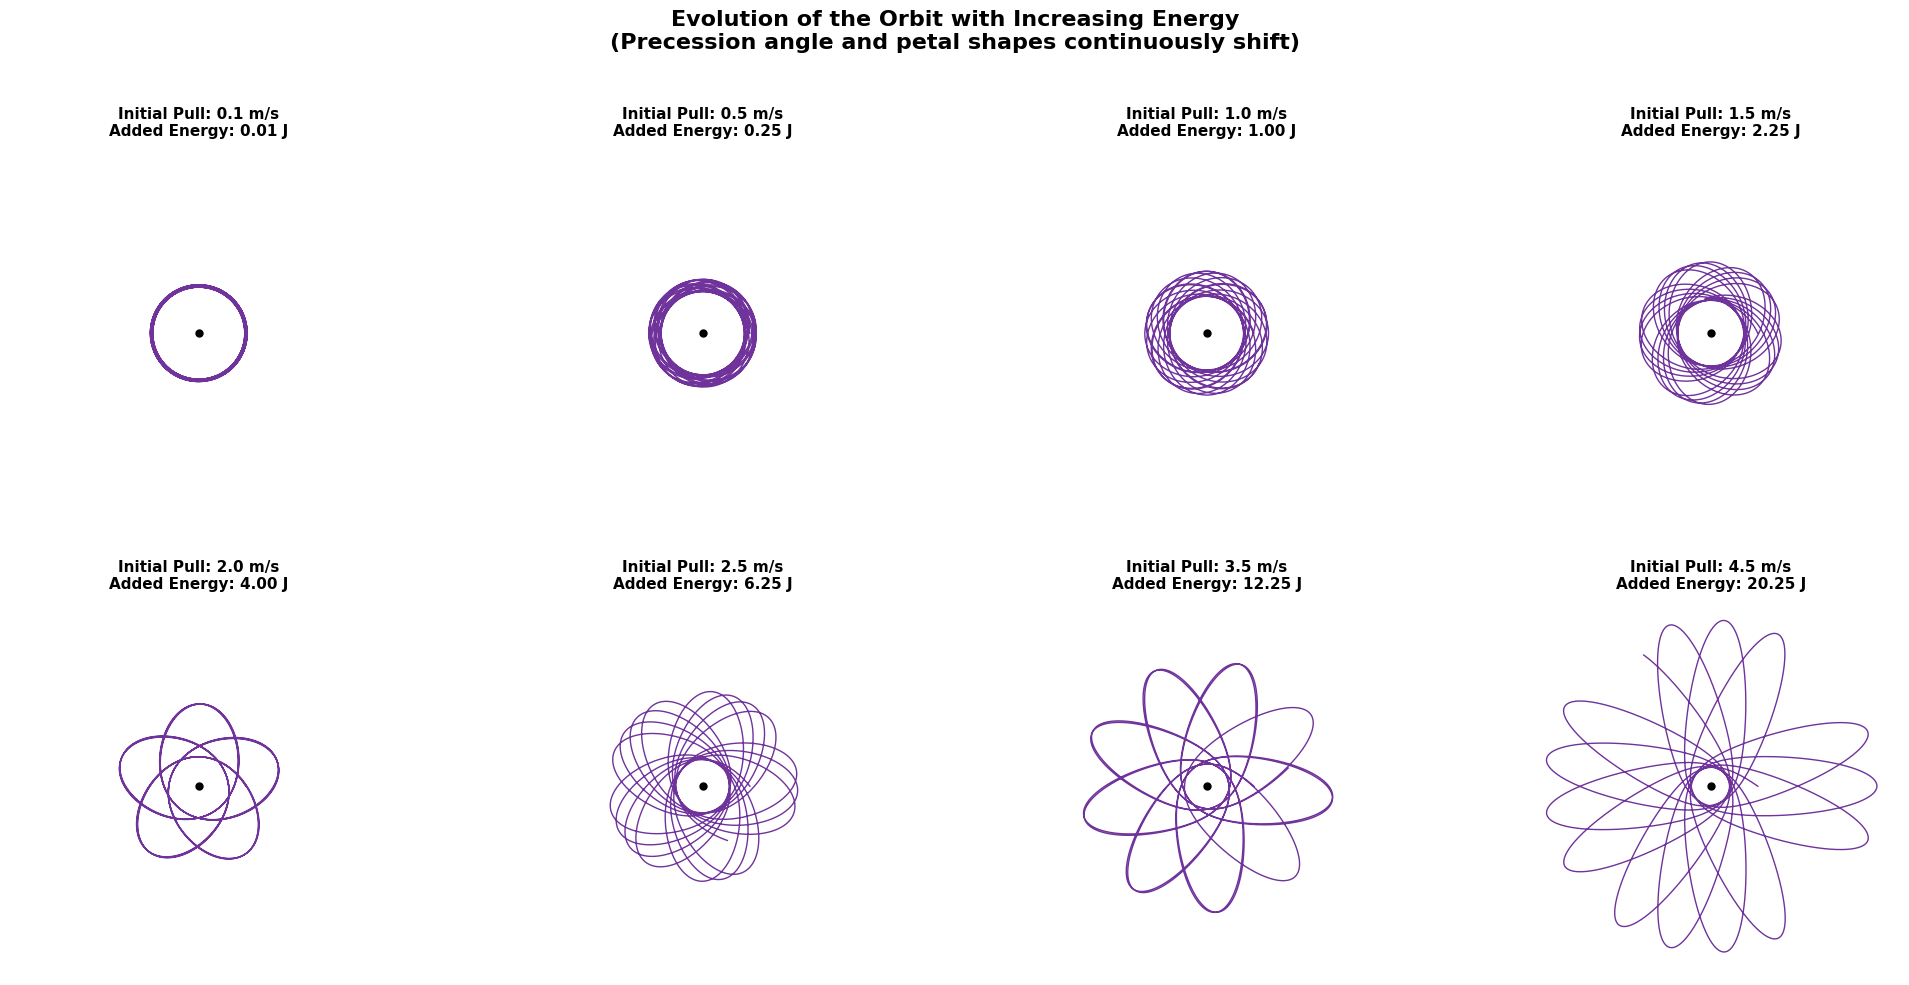

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ==========================================
# 1. System Parameters
# ==========================================
m1 = 1.0        # Mass of rotating disk (kg)
m2 = 1.0        # Mass of hanging object (kg)
g = 9.81        # Gravity (m/s^2)
R0 = 1.0        # Equilibrium radius (m)

# Conserved Angular Momentum for stable orbit at R0
L = np.sqrt(m1 * m2 * g * (R0**3))

# ==========================================
# 2. Equations of Motion
# ==========================================
def equations(t, state):
    r, r_dot, theta = state

    # Prevent numerical singularity at the origin
    if r < 1e-5:
        r = 1e-5

    # Radial equation: (m1 + m2)*r_ddot = L^2 / (m1 * r^3) - m2*g
    r_ddot = ((L**2) / (m1 * r**3) - m2 * g) / (m1 + m2)

    # Angular equation: theta_dot = L / (m1 * r^2)
    theta_dot = L / (m1 * r**2)

    return [r_dot, r_ddot, theta_dot]

# ==========================================
# 3. Simulation & Plotting Setup
# ==========================================
# We test 8 different initial radial velocities to inject increasing amounts of Energy
# v_r0 = 0.0 would be a perfect circle. As it increases, the oscillations get LARGER.
v_pulls = [0.1, 0.5, 1.0, 1.5, 2.0, 2.5, 3.5, 4.5]

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle("Evolution of the Orbit with Increasing Energy\n(Precession angle and petal shapes continuously shift)",
             fontsize=16, weight='bold', y=0.98)

t_span = (0, 35.0)  # Simulate 40 seconds of motion to allow dense orbits to fill the space
t_eval = np.linspace(t_span[0], t_span[1], 150000)

for ax, v_pull in zip(axes.flatten(), v_pulls):
    # Initial state: start at R0, give an inward radial push (v_pull), starting angle 0
    initial_state = [R0, -v_pull, 0.0]

    # Solve the exact nonlinear differential equations
    solution = solve_ivp(equations, t_span, initial_state, t_eval=t_eval, method='Radau', rtol=1e-8, atol=1e-8)

    r_t = solution.y[0]
    theta_t = solution.y[2]

    # Convert polar to Cartesian for plotting
    x_t = r_t * np.cos(theta_t)
    y_t = r_t * np.sin(theta_t)

    # Plot the trajectory
    ax.plot(x_t, y_t, color='indigo', linewidth=1.0, alpha=0.8)

    # Plot the central hole
    ax.plot(0, 0, 'ko', markersize=5)

    # Calculate the normalized added energy for the title
    # (Just radial kinetic energy added at the start)
    added_E = 0.5 * (m1 + m2) * v_pull**2

    ax.set_title(f"Initial Pull: {v_pull} m/s\nAdded Energy: {added_E:.2f} J", fontsize=11, weight='bold')
    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')  # Hide grid/axes to emphasize the geometric patterns

    # Keep the bounds consistent based on the largest orbit to show scale differences
    ax.set_xlim(-4.0, 4.0)
    ax.set_ylim(-4.0, 4.0)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.subplots_adjust(hspace=0.2, wspace=0.1)

# Display the grid of trajectories
plt.show()